
Conversion rates by device:
             sessions  orders  conversion_rate
device_type                                   
desktop        327027   27805             8.50
mobile         145844    4508             3.09

Repeated-session diagnostics:
Unique users: 394,318
Repeat users: 51,270 (13.0%)
Maximum sessions per user: 4

Unadjusted GEE:
                               GEE Regression Results                              
Dep. Variable:                   converted   No. Observations:               472871
Model:                                 GEE   No. clusters:                   394318
Method:                        Generalized   Min. cluster size:                   1
                      Estimating Equations   Max. cluster size:                   4
Family:                           Binomial   Mean cluster size:                 1.2
Dependence structure:         Exchangeable   Num. iterations:                     5
Date:                     Thu, 12 Nov 2026   Scale:                

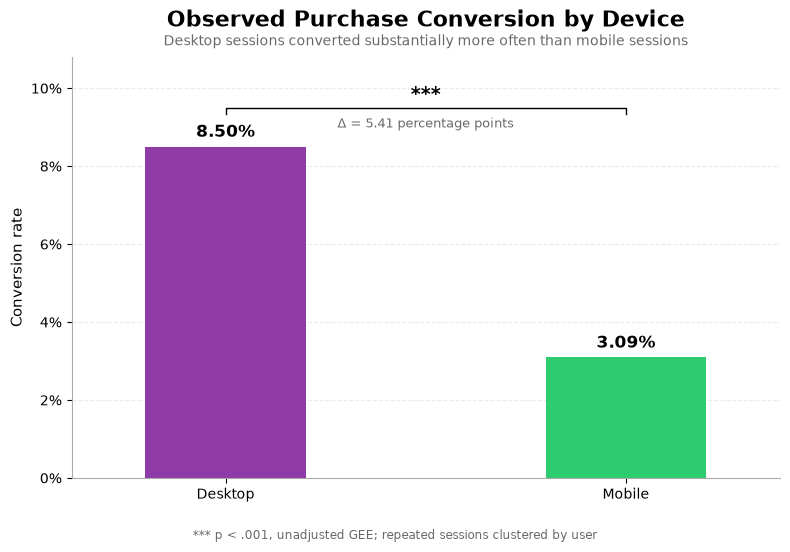

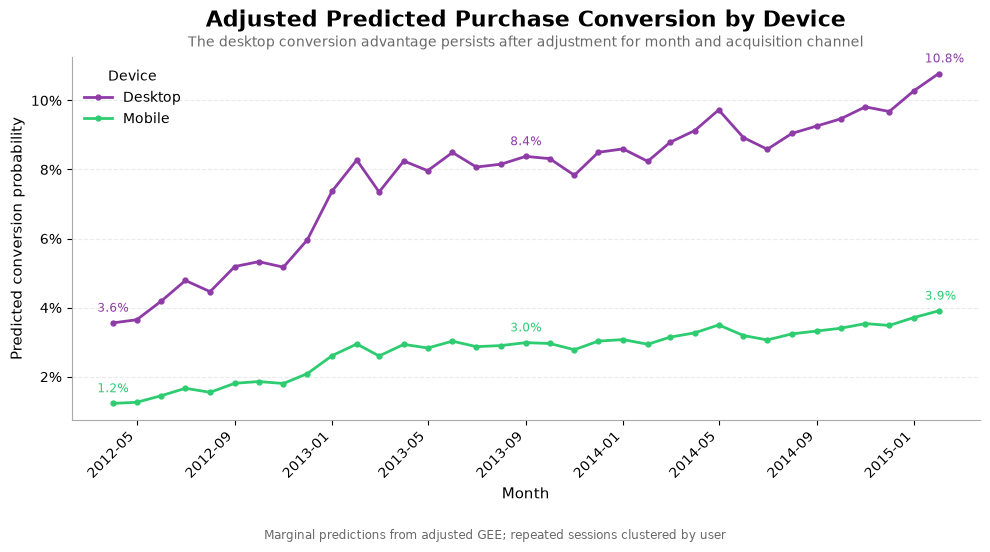

In [ ]:
# Device conversion analysis
# Uses Generalized Estimating Equations (GEE) to estimate the association
# between device type and purchase conversion while accounting for repeated
# sessions within users.

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


# Load session-level dataset created in SQL
BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR / "data" / "analysis_sessions.csv"

sessions = pd.read_csv(DATA_PATH)

# Prepare variables
sessions["created_at"] = pd.to_datetime(sessions["created_at"])
sessions["month"] = sessions["created_at"].dt.to_period("M").astype(str)


# Descriptive conversion rates by device
device_conversion = (
    sessions.groupby("device_type")["converted"]
    .agg(["count", "sum", "mean"])
    .rename(
        columns={
            "count": "sessions",
            "sum": "orders",
            "mean": "conversion_rate"
        }
    )
)

device_conversion["conversion_rate"] *= 100

print("\nConversion rates by device:")
print(device_conversion.round(2))


# Check repeated sessions within users.
# Because the dataset is session-level, the same user can appear multiple times.
# This violates the independence assumption of standard logistic regression
# and motivates clustering observations by user in the GEE models.

sessions_per_user = sessions.groupby("user_id").size()

repeat_users = (sessions_per_user > 1).sum()
repeat_user_pct = (
    repeat_users / sessions["user_id"].nunique() * 100
)

print("\nRepeated-session diagnostics:")
print(f"Unique users: {sessions['user_id'].nunique():,}")
print(f"Repeat users: {repeat_users:,} ({repeat_user_pct:.1f}%)")
print(f"Maximum sessions per user: {sessions_per_user.max()}")


# Unadjusted GEE model
model_unadjusted = smf.gee(
    "converted ~ C(device_type)",
    groups="user_id",
    data=sessions,
    family=sm.families.Binomial(),
    cov_struct=sm.cov_struct.Exchangeable()
)

result_unadjusted = model_unadjusted.fit()

print("\nUnadjusted GEE:")
print(result_unadjusted.summary())


# Adjusted GEE model.
# Calendar month and acquisition channel are included to account for
# differences in traffic composition over time and across acquisition sources.
# Repeated sessions remain clustered by user.

model_adjusted = smf.gee(
    "converted ~ C(device_type) + C(month) + C(channel)",
    groups="user_id",
    data=sessions,
    family=sm.families.Binomial(),
    cov_struct=sm.cov_struct.Exchangeable()
)

result_adjusted = model_adjusted.fit()

print("\nAdjusted GEE:")
print(result_adjusted.summary())


# Convert the mobile-vs-desktop coefficient into a
# desktop-vs-mobile adjusted odds ratio.
mobile_term = "C(device_type)[T.mobile]"

coef = result_adjusted.params[mobile_term]
ci_low, ci_high = result_adjusted.conf_int().loc[mobile_term]
p_value = result_adjusted.pvalues[mobile_term]

desktop_vs_mobile_or = np.exp(-coef)
desktop_vs_mobile_ci_low = np.exp(-ci_high)
desktop_vs_mobile_ci_high = np.exp(-ci_low)

p_text = "< .001" if p_value < .001 else f"= {p_value:.3f}"

print("\nAdjusted device effect:")
print(
    f"Desktop vs mobile OR: {desktop_vs_mobile_or:.2f} "
    f"(95% CI {desktop_vs_mobile_ci_low:.2f}–"
    f"{desktop_vs_mobile_ci_high:.2f}, "
    f"p {p_text})"
)

devices = ["Desktop", "Mobile"]

values = [
    device_conversion.loc["desktop", "conversion_rate"],
    device_conversion.loc["mobile", "conversion_rate"]
]

colors = ["#8E3BA8", "#2ECC71"]

x = [0, 0.65]

fig, ax = plt.subplots(figsize=(8, 5.5))

bars = ax.bar(
    x,
    values,
    color=colors,
    width=0.26
)

ax.set_xticks(x)
ax.set_xticklabels(devices)

ax.set_xlim(-0.25, 0.90)

ax.set_title(
    "Observed Purchase Conversion by Device",
    fontsize=16,
    weight="bold",
    pad=22
)

ax.text(
    0.5,
    1.02,
    "Desktop sessions converted substantially more often than mobile sessions",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
    color="dimgray"
)

ax.set_ylabel("Conversion rate", fontsize=11)
ax.set_ylim(0, 10.8)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: f"{y:.0f}%")
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    alpha=0.25
)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#AAAAAA")
ax.spines["bottom"].set_color("#AAAAAA")

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        weight="bold"
    )

gap = values[0] - values[1]

x1, x2 = x
y = 9.35
h = 0.15

ax.plot(
    [x1, x1, x2, x2],
    [y, y + h, y + h, y],
    color="black",
    linewidth=1
)

ax.text(
    (x1 + x2) / 2,
    y + h + 0.08,
    "***",
    ha="center",
    va="bottom",
    fontsize=14,
    weight="bold"
)

ax.text(
    (x1 + x2) / 2,
    y - 0.1,
    f"Δ = {gap:.2f} percentage points",
    ha="center",
    va="top",
    fontsize=9.5,
    color="dimgray"
)

fig.text(
    0.5,
    0.01,
    "*** p < .001, unadjusted GEE; repeated sessions clustered by user",
    ha="center",
    fontsize=8.5,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

# Marginal predicted conversion probabilities by month and device.
# For each month, preserve the observed acquisition-channel distribution,
# then predict every session once as desktop and once as mobile.
# Averaging these predictions gives device-specific probabilities standardized
# to the same observed channel mix within each month.

# Use complete months only for the time-series visualization.
# The fitted GEE model above still uses the full session-level dataset.

plot_sessions = sessions[
    (sessions["month"] >= "2012-04") &
    (sessions["month"] <= "2015-02")
].copy()

prediction_rows = []

for month in sorted(plot_sessions["month"].unique()):
    month_data = plot_sessions[
        plot_sessions["month"] == month
    ].copy()

    for device in ["desktop", "mobile"]:
        prediction_data = month_data.copy()
        prediction_data["device_type"] = device

        predicted_probability = result_adjusted.predict(
            prediction_data
        ).mean()

        prediction_rows.append({
            "month": month,
            "device_type": device,
            "predicted_conversion": predicted_probability
        })

predictions = pd.DataFrame(prediction_rows)

predictions["month"] = pd.to_datetime(predictions["month"])
predictions["predicted_conversion"] *= 100

predictions.head()

# Plot adjusted predicted conversion probabilities by month and device
fig, ax = plt.subplots(figsize=(10, 5.5))

colors = {
    "desktop": "#8E3BA8",
    "mobile": "#2ECC71"
}

for device in ["desktop", "mobile"]:
    device_predictions = predictions[
        predictions["device_type"] == device
    ]

    ax.plot(
        device_predictions["month"],
        device_predictions["predicted_conversion"],
        marker="o",
        markersize=3.5,
        linewidth=2,
        color=colors[device],
        label=device.capitalize()
    )

ax.set_title(
    "Adjusted Predicted Purchase Conversion by Device",
    fontsize=16,
    weight="bold",
    pad=22
)

ax.text(
    0.5,
    1.02,
    "The desktop conversion advantage persists after adjustment for month and acquisition channel",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
    color="dimgray"
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Predicted conversion probability", fontsize=11)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: f"{y:.0f}%")
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    alpha=0.25
)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#AAAAAA")
ax.spines["bottom"].set_color("#AAAAAA")

ax.legend(
    title="Device",
    frameon=False,
    loc="upper left"
)

unique_months = sorted(predictions["month"].unique())

selected_months = [
    unique_months[0],
    unique_months[len(unique_months) // 2],
    unique_months[-1]
]

for device in ["desktop", "mobile"]:
    selected = predictions[
        (predictions["device_type"] == device) &
        (predictions["month"].isin(selected_months))
    ]

    for _, row in selected.iterrows():

        if row["month"] == selected_months[-1]:
            offset = (-10, 8)
            horizontal_alignment = "left"
        else:
            offset = (0, 8)
            horizontal_alignment = "center"

        ax.annotate(
            f"{row['predicted_conversion']:.1f}%",
            (row["month"], row["predicted_conversion"]),
            xytext=offset,
            textcoords="offset points",
            ha=horizontal_alignment,
            fontsize=8.5,
            color=colors[device]
        )

plt.xticks(rotation=45, ha="right")

fig.text(
    0.5,
    0.01,
    "Marginal predictions from adjusted GEE; repeated sessions clustered by user",
    ha="center",
    fontsize=8.5,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()